# How long will a health commodity order take to arrive?

**Mission:** My mission is to improve access to essential medicines and health supplies in Rwanda and the rest of Africa, so clinics don't run out of the things patients need.

**Use case:** When a country's medical store (for example Rwanda Medical Supply) or a national HIV or malaria program orders commodities through a donor supply chain, they need to know roughly how many days the order will take to arrive. If they underestimate it, they reorder too late and health facilities end up with stockouts. In this notebook I train a model that predicts the **order cycle time in days** (from the day the order is entered to the day it is delivered) using information that is already known when the order is placed. Supply chain planners would use the prediction to decide when to place the next order.

**Dataset:** USAID GHSC-PSM Health Commodity Delivery Dataset. It was published by USAID on data.usaid.gov and has one row per order line delivered by the Global Health Supply Chain Program (Procurement and Supply Management) between 2016 and 2024: 43,396 rows, 104 columns and 96 countries (1,058 of the rows are orders for Rwanda). The data.usaid.gov portal went offline in 2025, so I use the archived copy of the official CSV from the Wayback Machine.

- Original page: https://data.usaid.gov/Health/USAID-GHSC-PSM-Health-Commodity-Delivery-Dataset/tikn-bfy4
- Archived CSV: https://web.archive.org/web/20250129194228/https://data.usaid.gov/api/views/tikn-bfy4/rows.csv?accessType=DOWNLOAD

In [1]:
import os
import urllib.request

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
RANDOM_STATE = 42

## 1. Loading the data

The CSV is about 46 MB. The first time the notebook runs it downloads the file from the archive and keeps a local copy, after that it just reads the local file.

In [2]:
DATA_URL = "https://web.archive.org/web/20250129194228id_/https://data.usaid.gov/api/views/tikn-bfy4/rows.csv?accessType=DOWNLOAD"
DATA_FILE = "ghsc_psm_deliveries.csv"

if not os.path.exists(DATA_FILE):
    print("Downloading the dataset...")
    urllib.request.urlretrieve(DATA_URL, DATA_FILE)

raw = pd.read_csv(DATA_FILE, low_memory=False)
print(raw.shape)
raw.head(3)

(43396, 104)


,ROPOLine,Task Order,Condom Adjusted Task Order,Country,RO Number,PO DO IO Number,Order Number,Prime Line Number,Status Name,TLP Indicator,Order Type,Fulfillment Method,Transportation Mode,Item Tracer Category,Product Category,...,Max Pick Up Date,Max Ship Date,Max Departure Date,Max Arrival Date,Order Cycle Time,RO Validation,Sourcing and Planning,USAID Approval,Process PO/DO,Manufacture,Pick Up,Deliver,Quality Assurance,Reason Code,Reason Code Duration
0,RO10026301PO100041611,TO1,TO1,Haiti,RO10026301,PO10004161,PO10004161,1,Shipment Delivered,DCP,Purchase Order,Direct Drop,Land,Laboratory,Laboratory Reagents,...,NaN,"Thursday, October 5, 2017",NaN,NaN,98,NaN,NaN,0.0,35.0,NaN,NaN,NaN,NaN,NaN,NaN
1,RO10043181PO100076996,TO1,TO1,Zambia,RO10043181,PO10007699,PO10007699,6,Shipment Delivered,DCP,Purchase Order,Direct Drop,Land,Laboratory,Laboratory Reagents,...,NaN,"Wednesday, July 18, 2018",NaN,NaN,245,NaN,NaN,3.0,35.0,NaN,NaN,NaN,NaN,NaN,NaN
2,RO10022196PO100016001,TO1,TO1,Mozambique,RO10022196,PO10001600,PO10001600,1,Shipment Delivered,DCP,Purchase Order,Direct Drop,Land,Laboratory,Laboratory Reagents,...,NaN,"Tuesday, June 6, 2017",NaN,NaN,128,NaN,NaN,13.0,209.0,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
# quick look at the columns I care about
cols_to_look_at = ["Country", "Order Type", "Fulfillment Method", "Transportation Mode", "Product Category",
                   "D365 Health Element", "Vendor Incoterm", "Destination Incoterm", "Ordered Quantity",
                   "Illustrative Price", "Estimated Lead Time in Days", "Order Entry Date", "Order Cycle Time"]
raw[cols_to_look_at].info()

<class 'pandas.DataFrame'>
RangeIndex: 43396 entries, 0 to 43395
Data columns (total 13 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Country                      43396 non-null  str    
 1   Order Type                   43396 non-null  str    
 2   Fulfillment Method           43396 non-null  str    
 3   Transportation Mode          43396 non-null  str    
 4   Product Category             43396 non-null  str    
 5   D365 Health Element          42842 non-null  str    
 6   Vendor Incoterm              39209 non-null  str    
 7   Destination Incoterm         37533 non-null  str    
 8   Ordered Quantity             43396 non-null  int64  
 9   Illustrative Price           43271 non-null  float64
 10  Estimated Lead Time in Days  31725 non-null  float64
 11  Order Entry Date             43396 non-null  str    
 12  Order Cycle Time             43396 non-null  int64  
dtypes: float64(2), int64(2), st

There are 104 columns but a lot of them are not useful for my question. Many are ID numbers (order numbers, PO numbers, product IDs), and a big group of them are dates and durations that only exist **after** the order has been delivered (actual delivery date, days late, on-time flags, how long each stage took). A planner doesn't have those when placing an order, so I can't use them as inputs.

`Order Cycle Time` is already in days, so that is my target.

## 2. Cleaning and building the working table

In [4]:
df = raw.copy()

# only orders that were actually delivered, and cycle times that make sense
df = df[df["Status Name"] == "Shipment Delivered"]
df = df[df["Order Cycle Time"] > 0]
print("rows after removing undelivered / negative cycle times:", len(df))

# the order date looks like "Thursday, November 17, 2016"
order_date = pd.to_datetime(df["Order Entry Date"], format="%A, %B %d, %Y")

data = pd.DataFrame({
    "country": df["Country"],
    "order_type": df["Order Type"],
    "transport_mode": df["Transportation Mode"],
    "product_category": df["Product Category"],
    "health_element": df["D365 Health Element"],
    "vendor_incoterm": df["Vendor Incoterm"],
    "destination_incoterm": df["Destination Incoterm"],
    "ordered_quantity": df["Ordered Quantity"],
    "unit_price": df["Illustrative Price"],
    "est_lead_time_days": df["Estimated Lead Time in Days"],
    "order_year": order_date.dt.year,
    "order_month": order_date.dt.month,
    "order_cycle_days": df["Order Cycle Time"],
})

# columns I only keep for now to look at in the heatmap (they get dropped later)
leaky = df[["Shipped Quantity", "Manufacture", "Pick Up", "Deliver"]].rename(columns={
    "Shipped Quantity": "shipped_quantity", "Manufacture": "manufacture_days",
    "Pick Up": "pickup_days", "Deliver": "deliver_days"})

data.isna().sum()

rows after removing undelivered / negative cycle times: 43121


country                     0
order_type                  0
transport_mode              0
product_category            0
health_element            550
vendor_incoterm          4182
destination_incoterm     5809
ordered_quantity            0
unit_price                125
est_lead_time_days      11587
order_year                  0
order_month                 0
order_cycle_days            0
dtype: int64

Things I noticed while cleaning:

- `est_lead_time_days` is missing for about a quarter of the rows. It's the lead time the program estimates when the order is placed, and in my first checks it was the strongest numeric predictor, so I drop rows where it's missing instead of filling it with a made-up value. There are still more than 30,000 rows left after that.
- `vendor_incoterm` has 300+ messy spellings (like `FCA - SUWANEE`). The first three letters are the actual incoterm, so I keep those and put the rare ones in "Other".
- A few categories only appear a handful of times (countries with 1 or 2 orders, typos in `health_element`). I group anything rare into "Other" so the one-hot encoding doesn't create lots of almost-empty columns.

In [5]:
data["vendor_incoterm"] = data["vendor_incoterm"].str[:3]


def group_rare(col, min_count, other_label="Other"):
    counts = col.value_counts()
    keep = counts[counts >= min_count].index
    return col.where(col.isin(keep), other_label)


for c in ["vendor_incoterm", "destination_incoterm", "health_element"]:
    data[c] = data[c].fillna("Unknown")

data["country"] = group_rare(data["country"], 30)
data["product_category"] = group_rare(data["product_category"], 30, other_label="Others")
data["vendor_incoterm"] = group_rare(data["vendor_incoterm"], 100)
data["destination_incoterm"] = group_rare(data["destination_incoterm"], 100)
data["health_element"] = group_rare(data["health_element"], 100)

keep_rows = data["est_lead_time_days"].notna() & data["unit_price"].notna() & (data["ordered_quantity"] > 0)
data = data[keep_rows]
leaky = leaky[keep_rows]
print(data.shape)
data.describe().round(1)

(31529, 13)


,ordered_quantity,unit_price,est_lead_time_days,order_year,order_month,order_cycle_days
count,31529.0,31529.0,31529.0,31529.0,31529.0,31529.0
mean,26243.6,511.2,162.3,2020.1,6.8,247.5
std,109215.4,4628.5,84.0,1.9,3.4,127.4
min,1.0,0.0,0.0,2016.0,1.0,1.0
25%,24.0,7.5,105.0,2018.0,4.0,156.0
50%,193.0,48.0,147.0,2020.0,7.0,225.0
75%,3492.0,180.0,203.0,2022.0,10.0,318.0
max,2890944.0,193455.0,1260.0,2024.0,12.0,1164.0


## 3. Exploring the data

### Distribution of the target

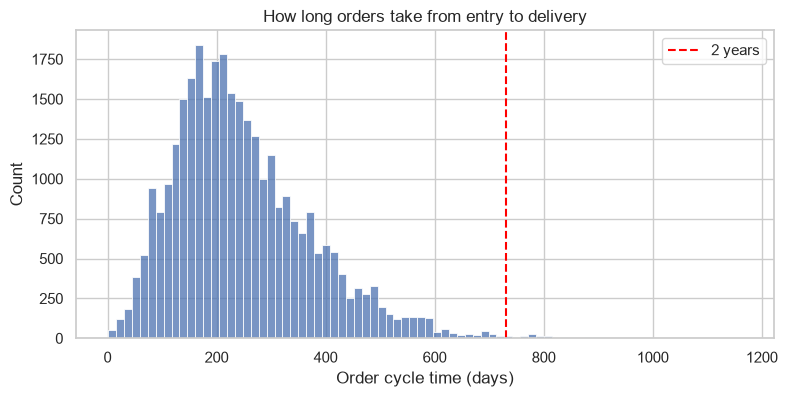

median: 225.0 | skew: 1.02
orders over 2 years: 119


In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data["order_cycle_days"], bins=80, ax=ax)
ax.axvline(730, color="red", linestyle="--", label="2 years")
ax.set_xlabel("Order cycle time (days)")
ax.set_title("How long orders take from entry to delivery")
ax.legend()
plt.show()

print("median:", data["order_cycle_days"].median(), "| skew:", round(data["order_cycle_days"].skew(), 2))
print("orders over 2 years:", (data["order_cycle_days"] > 730).sum())

Most orders take between about 100 and 400 days, and the median is 225 days, so a typical order takes more than 7 months to arrive. The distribution has a long right tail (skew is about 1) with a few orders taking more than 2 years. Only 119 orders are above 730 days. They're probably special cases I can't predict from the inputs anyway, so I removed them so they don't dominate the squared error. I kept the target in days instead of taking the log, because the skew isn't extreme and it's easier to explain the error in days.

In [7]:
data = data[data["order_cycle_days"] <= 730]
leaky = leaky.loc[data.index]
print(data.shape)

(31410, 13)


### Quantity and price

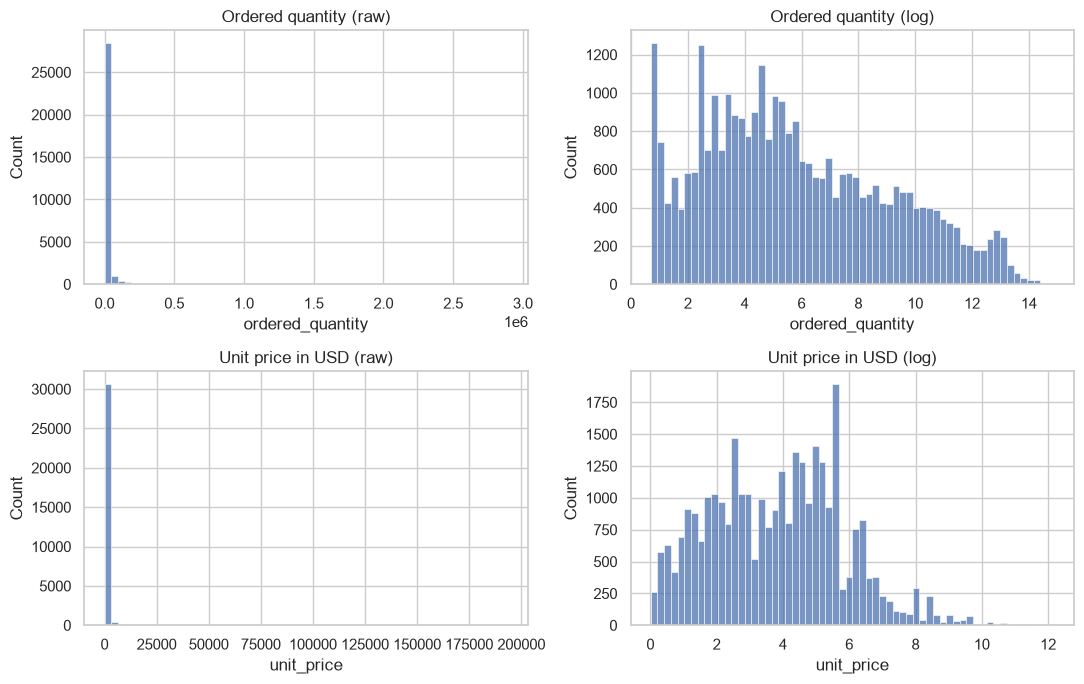

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
sns.histplot(data["ordered_quantity"], bins=60, ax=axes[0, 0])
axes[0, 0].set_title("Ordered quantity (raw)")
sns.histplot(np.log1p(data["ordered_quantity"]), bins=60, ax=axes[0, 1])
axes[0, 1].set_title("Ordered quantity (log)")
sns.histplot(data["unit_price"], bins=60, ax=axes[1, 0])
axes[1, 0].set_title("Unit price in USD (raw)")
sns.histplot(np.log1p(data["unit_price"]), bins=60, ax=axes[1, 1])
axes[1, 1].set_title("Unit price in USD (log)")
plt.tight_layout()
plt.show()

The raw quantity and price are extremely skewed: almost everything is in the first bar, and a few orders go up to almost 3 million units or $190,000 per unit. After a log transform both are much more spread out. So in the preprocessing I apply `log1p` to `ordered_quantity` and `unit_price` before scaling. This matters mostly for the linear models, otherwise a handful of huge orders would pull the line.

### Correlation heatmap

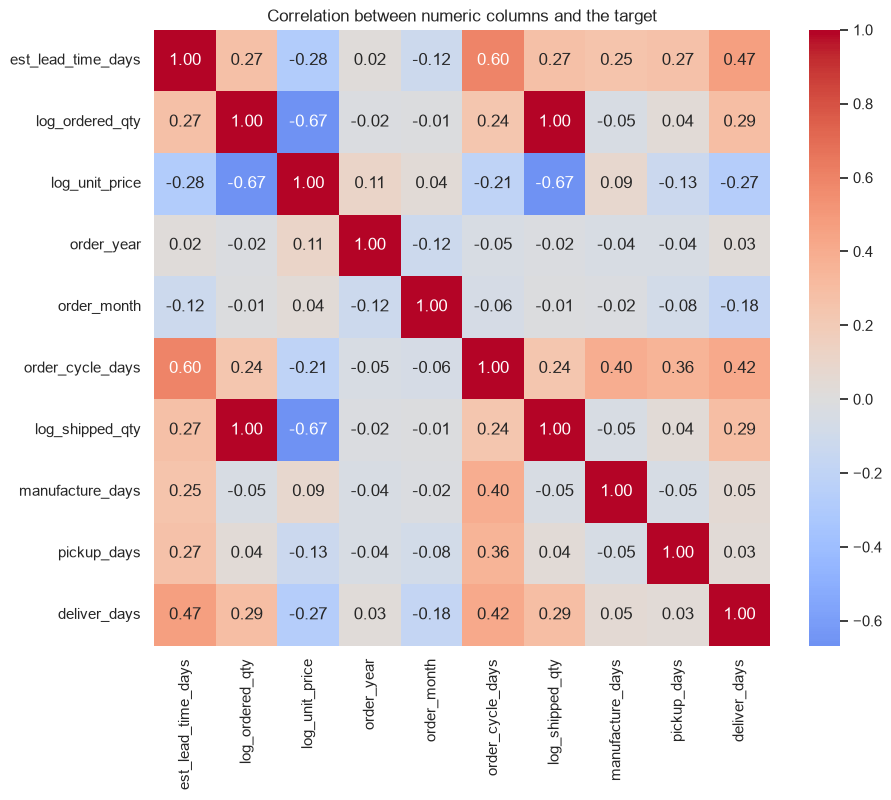

In [9]:
heat = data[["est_lead_time_days", "ordered_quantity", "unit_price", "order_year", "order_month", "order_cycle_days"]].copy()
heat["ordered_quantity"] = np.log1p(heat["ordered_quantity"])
heat["unit_price"] = np.log1p(heat["unit_price"])
heat["shipped_quantity"] = np.log1p(leaky["shipped_quantity"])
heat["manufacture_days"] = leaky["manufacture_days"]
heat["pickup_days"] = leaky["pickup_days"]
heat["deliver_days"] = leaky["deliver_days"]
heat = heat.rename(columns={"ordered_quantity": "log_ordered_qty", "unit_price": "log_unit_price",
                            "shipped_quantity": "log_shipped_qty"})

plt.figure(figsize=(10, 8))
sns.heatmap(heat.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation between numeric columns and the target")
plt.show()

`est_lead_time_days` has the strongest correlation with the target (0.60), so it's the most important numeric input and the one I use for the scatter plots later. Log quantity (0.24) and log price (-0.21) are weaker but still useful. They are correlated with each other (-0.67, big orders are usually cheap items like condoms or test kits) but not so much that I need to drop one.

`log_shipped_qty` is exactly 1.00 with `log_ordered_qty`, so it adds nothing, and it's only known after shipping anyway, so I dropped it. The stage durations (`manufacture_days`, `pickup_days`, `deliver_days`) correlate with the target (0.36 to 0.42), but they are parts of the cycle time itself and only exist after delivery. Using them would be leakage, so I dropped them too. `order_year` and `order_month` have almost no linear correlation, but I kept them because delays could change by year (COVID for example) in a way that isn't a straight line, which a tree can still pick up.

### Does the target change across the categorical columns?

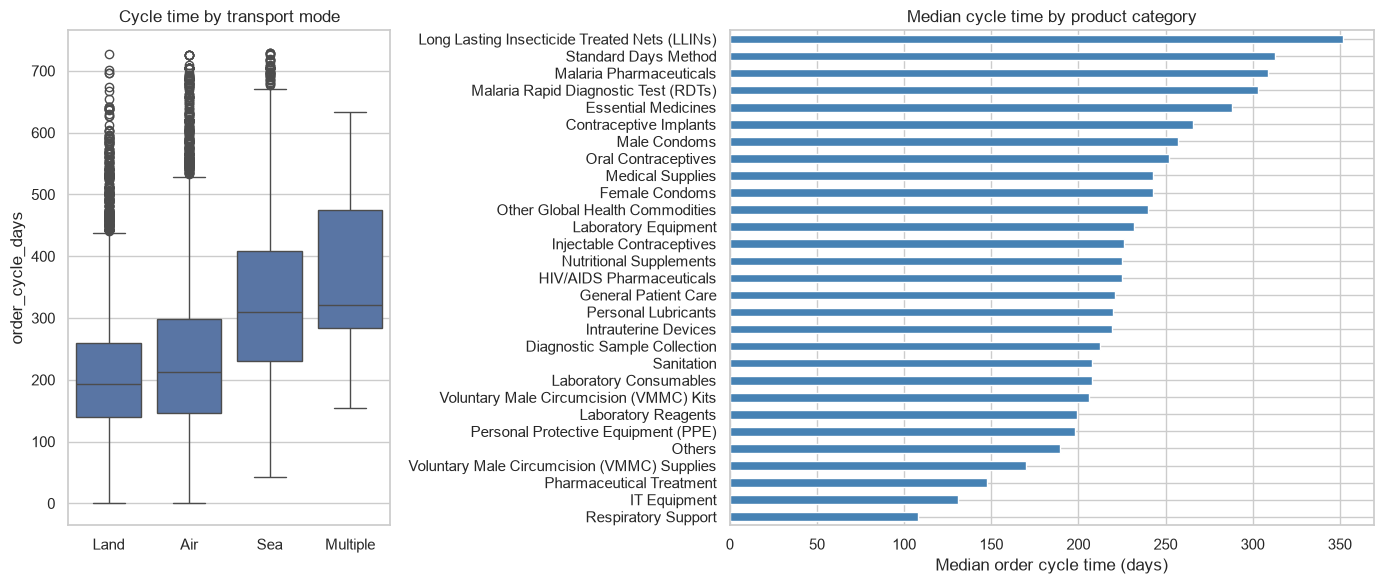

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [1, 2]})

sns.boxplot(data=data, x="transport_mode", y="order_cycle_days", ax=axes[0],
            order=["Land", "Air", "Sea", "Multiple"])
axes[0].set_title("Cycle time by transport mode")
axes[0].set_xlabel("")

by_product = data.groupby("product_category")["order_cycle_days"].median().sort_values()
by_product.plot(kind="barh", ax=axes[1], color="steelblue")
axes[1].set_title("Median cycle time by product category")
axes[1].set_xlabel("Median order cycle time (days)")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

Transport mode clearly changes the cycle time: sea and multiple-mode shipments have a median around 300+ days, while land and air are around 200. Product category matters a lot too, from about 110 days for respiratory support up to about 350 days for mosquito nets (LLINs), which makes sense because nets are bulky and usually go by sea. So I kept the categorical columns and one-hot encode them. This also made me expect a tree model to do better than a straight line, since the categories don't have a natural numeric order.

## 4. Feature engineering summary

**Dropped:**
- ID columns (`ROPOLine`, `RO Number`, `PO DO IO Number`, `Order Number`, `Product ID`, ...): they're just identifiers.
- Everything that is only known after delivery: the actual dates, `Shipped Quantity`, `Average Days Late`, the on-time / in-full flags, `Line Delivery Status` and the stage durations. These would leak the answer.
- `Fulfillment Method`: it duplicates `Order Type` exactly (every Distribution Order is RDC and every Purchase Order is Direct Drop).
- `Product_Name`: 4,730 different values, too many to one-hot encode. `Product Category` carries the same idea in a usable way.
- `Delivery Progress`: same value in every row.
- Other admin columns (task order, funding source codes, unit of measure...) that a planner wouldn't really use or that repeat other columns.

**Kept (12 inputs):** 7 categorical (country, order type, transport mode, product category, health element, vendor incoterm, destination incoterm) and 5 numeric (ordered quantity, unit price, estimated lead time, order year, order month).

**Which features matter most:** from the heatmap, estimated lead time is by far the strongest numeric feature. From the plots above, transport mode and product category also make a big difference. I check this again at the end with permutation importance on the best model.

In [11]:
cat_features = ["country", "order_type", "transport_mode", "product_category", "health_element",
                "vendor_incoterm", "destination_incoterm"]
log_features = ["ordered_quantity", "unit_price"]
num_features = ["est_lead_time_days", "order_year", "order_month"]
FEATURES = cat_features + log_features + num_features
TARGET = "order_cycle_days"

data = data[FEATURES + [TARGET]].reset_index(drop=True)
print(len(FEATURES), "input features,", len(data), "rows")
data.head()

12 input features, 31410 rows


,country,order_type,transport_mode,product_category,health_element,vendor_incoterm,destination_incoterm,ordered_quantity,unit_price,est_lead_time_days,order_year,order_month,order_cycle_days
0,Zambia,Purchase Order,Land,Laboratory Reagents,HIV/AIDS,DDP,DDP,191,348.01,91.0,2017,11,245
1,Zambia,Purchase Order,Land,Laboratory Reagents,HIV/AIDS,DDP,DDP,210,137.00,140.0,2018,8,501
2,Mozambique,Purchase Order,Land,Laboratory Consumables,HIV/AIDS,DDP,DDP,306,260.00,154.0,2017,10,151
3,Uganda,Purchase Order,Land,Laboratory Consumables,HIV/AIDS,DDP,DDP,150,260.00,70.0,2017,10,153
4,Mozambique,Purchase Order,Land,Laboratory Consumables,HIV/AIDS,DDP,Unknown,65,260.00,0.0,2017,6,197


## 5. Train/test split and standardising

I split 80/20. The preprocessing is inside a `ColumnTransformer`:

- categorical columns -> one-hot encoding (`handle_unknown="ignore"` so a new category in the API doesn't crash it)
- quantity and price -> log, then standardise
- the other numeric columns -> standardise

The transformer is fitted on the **training set only** and then used to transform the test set, so nothing from the test set leaks into the scaling.

In [12]:
X = data[FEATURES]
y = data[TARGET]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)


def make_preprocessor():
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_features),
        ("log", Pipeline([("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                          ("scale", StandardScaler())]), log_features),
        ("num", StandardScaler(), num_features),
    ])


preprocessor = make_preprocessor()
X_train_p = preprocessor.fit_transform(X_train)   # fit on train only
X_test_p = preprocessor.transform(X_test)
y_train_np = y_train.to_numpy()
y_test_np = y_test.to_numpy()

print("train:", X_train_p.shape, " test:", X_test_p.shape)

train: (25128, 118)  test: (6282, 118)


For tuning I don't want to look at the test set, so I take 20% of the training data as a validation set. It gets its own preprocessor fitted only on the remaining 80%.

In [13]:
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=RANDOM_STATE)
tune_prep = make_preprocessor()
X_tr_p = tune_prep.fit_transform(X_tr)
X_val_p = tune_prep.transform(X_val)
y_tr_np, y_val_np = y_tr.to_numpy(), y_val.to_numpy()
print(X_tr_p.shape, X_val_p.shape)

(20102, 118) (5026, 118)


## 6. Model 1: linear regression with gradient descent (SGDRegressor)

scikit-learn doesn't save the loss after each epoch, so I train with `partial_fit` in a loop. One call to `partial_fit` is one pass (epoch) over the data. I shuffle the rows before every epoch and save the MSE on both sets after each one.

In [14]:
def train_sgd(X_a, y_a, X_b, y_b, lr, alpha, epochs, seed=RANDOM_STATE):
    model = SGDRegressor(learning_rate="constant", eta0=lr, penalty="l2", alpha=alpha, random_state=seed)
    rng = np.random.default_rng(seed)
    losses_a, losses_b = [], []
    for epoch in range(epochs):
        order = rng.permutation(len(y_a))
        model.partial_fit(X_a[order], y_a[order])
        losses_a.append(mean_squared_error(y_a, model.predict(X_a)))
        losses_b.append(mean_squared_error(y_b, model.predict(X_b)))
    return model, losses_a, losses_b

### Tuning learning rate, regularisation and number of epochs

I try 3 learning rates and 4 regularisation strengths (`alpha`, L2 penalty), and train each one for 60 epochs. For each combination I record the epoch where the validation MSE was lowest, which tells me how many epochs to use.

In [15]:
learning_rates = [0.0001, 0.001, 0.01]
alphas = [0.0001, 0.001, 0.01, 0.1]
MAX_EPOCHS = 60

results = []
curves = {}
for lr in learning_rates:
    for alpha in alphas:
        _, tr_loss, val_loss = train_sgd(X_tr_p, y_tr_np, X_val_p, y_val_np, lr, alpha, MAX_EPOCHS)
        best_epoch = int(np.argmin(val_loss)) + 1
        results.append({"learning_rate": lr, "alpha": alpha, "best_epoch": best_epoch,
                        "val_mse_at_best_epoch": min(val_loss), "val_mse_after_60": val_loss[-1]})
        curves[(lr, alpha)] = val_loss

tuning = pd.DataFrame(results).sort_values("val_mse_at_best_epoch").reset_index(drop=True)
tuning.round({"val_mse_at_best_epoch": 1, "val_mse_after_60": 1})

,learning_rate,alpha,best_epoch,val_mse_at_best_epoch,val_mse_after_60
0,0.0010,0.0001,41,8488.2,8489.2
1,0.0010,0.0010,41,8494.4,8494.6
2,0.0001,0.0001,60,8557.0,8557.0
3,0.0001,0.0010,60,8561.8,8561.8
4,0.0010,0.0100,41,8598.1,8598.7
5,0.0100,0.0001,26,8612.5,8898.6
6,0.0100,0.0010,26,8612.8,8903.3
7,0.0001,0.0100,60,8623.1,8623.1
8,0.0100,0.0100,5,8724.5,9000.9
9,0.0010,0.1000,25,8964.2,8993.2


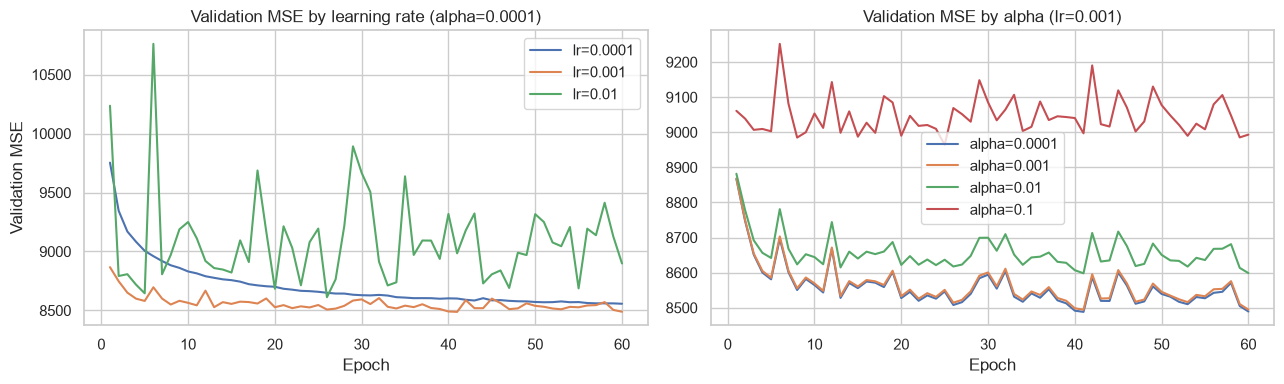

In [16]:
best_alpha = tuning.iloc[0]["alpha"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for lr in learning_rates:
    axes[0].plot(range(1, MAX_EPOCHS + 1), curves[(lr, best_alpha)], label=f"lr={lr}")
axes[0].set_title(f"Validation MSE by learning rate (alpha={best_alpha})")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Validation MSE")
axes[0].legend()

best_lr = tuning.iloc[0]["learning_rate"]
for alpha in alphas:
    axes[1].plot(range(1, MAX_EPOCHS + 1), curves[(best_lr, alpha)], label=f"alpha={alpha}")
axes[1].set_title(f"Validation MSE by alpha (lr={best_lr})")
axes[1].set_xlabel("Epoch")
axes[1].legend()
plt.tight_layout()
plt.show()

What I found:
- **Learning rate:** 0.01 is too big. The validation loss jumps around a lot (up to about 10,700) and never settles. 0.0001 is stable but slow and is still going down after 60 epochs. 0.001 reaches the lowest loss within about 10 epochs and stays there, so I picked it.
- **Regularisation (alpha):** 0.0001 and 0.001 give almost the same result, 0.01 is slightly worse and 0.1 is clearly worse (around 9,000) because the penalty shrinks the weights too much and the model underfits. With 25,000 rows and only 118 columns after encoding, the linear model isn't overfitting, so strong regularisation doesn't help.
- **Epochs:** with lr=0.001 the loss is basically flat after 10-15 epochs. The best validation score was at epoch 41, so the final model trains for 41 epochs.

### Final SGD model and loss curve

Now I train the best setting on the full training set and record train and test MSE after every epoch.

lr=0.001, alpha=0.0001, epochs=41


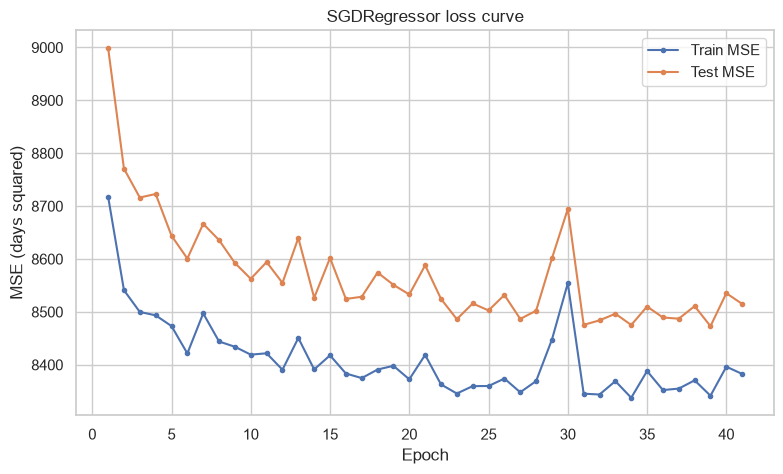

final train MSE: 8382.7 | final test MSE: 8515.0


In [17]:
best_lr = float(tuning.iloc[0]["learning_rate"])
best_alpha = float(tuning.iloc[0]["alpha"])
best_epochs = int(tuning.iloc[0]["best_epoch"])
print(f"lr={best_lr}, alpha={best_alpha}, epochs={best_epochs}")

sgd, sgd_train_loss, sgd_test_loss = train_sgd(X_train_p, y_train_np, X_test_p, y_test_np,
                                               best_lr, best_alpha, best_epochs)

plt.figure(figsize=(9, 5))
plt.plot(range(1, best_epochs + 1), sgd_train_loss, marker="o", markersize=3, label="Train MSE")
plt.plot(range(1, best_epochs + 1), sgd_test_loss, marker="o", markersize=3, label="Test MSE")
plt.xlabel("Epoch")
plt.ylabel("MSE (days squared)")
plt.title("SGDRegressor loss curve")
plt.legend()
plt.show()

print("final train MSE:", round(sgd_train_loss[-1], 1), "| final test MSE:", round(sgd_test_loss[-1], 1))

Both curves drop fast in the first 5 epochs and then flatten out around 8,400-8,500. The test loss stays just a little above the train loss the whole time, so the linear model is not overfitting. It's underfitting: a straight line can't capture much more of the pattern however long I train it. The small spikes (like at epoch 30) are normal for SGD with a constant learning rate, because it updates the weights one row at a time.

## 7. Model 2: linear regression (closed form)

Same linear model, but `LinearRegression` solves for the weights directly with least squares instead of gradient descent. If my SGD is working properly the two should end up with similar errors.

In [18]:
lin = LinearRegression()
lin.fit(X_train_p, y_train_np)
print("train MSE:", round(mean_squared_error(y_train_np, lin.predict(X_train_p)), 1))
print("test MSE:", round(mean_squared_error(y_test_np, lin.predict(X_test_p)), 1))

train MSE: 8312.9
test MSE: 8425.0


## 8. Model 3: decision tree

A single tree overfits very easily, so I check a few values of `max_depth` on the validation set first.

In [19]:
tree_scores = []
for depth in [4, 6, 8, 10, 12, 15, 20, None]:
    t = DecisionTreeRegressor(max_depth=depth, random_state=RANDOM_STATE).fit(X_tr_p, y_tr_np)
    tree_scores.append({"max_depth": "no limit" if depth is None else depth,
                        "train_mse": mean_squared_error(y_tr_np, t.predict(X_tr_p)),
                        "val_mse": mean_squared_error(y_val_np, t.predict(X_val_p))})
tree_scores = pd.DataFrame(tree_scores)
tree_scores.round(1)

,max_depth,train_mse,val_mse
0,4,8874.6,9089.4
1,6,7942.0,8390.1
2,8,7048.2,7898.8
3,10,6011.5,7388.0
4,12,4943.7,6957.0
5,15,3445.1,6706.8
6,20,1721.0,6789.4
7,no limit,174.4,7393.6


In [20]:
best_depth = tree_scores.loc[tree_scores["val_mse"].idxmin(), "max_depth"]
best_depth = None if best_depth == "no limit" else int(best_depth)
tree = DecisionTreeRegressor(max_depth=best_depth, random_state=RANDOM_STATE)
tree.fit(X_train_p, y_train_np)
print("max_depth:", best_depth)
print("train MSE:", round(mean_squared_error(y_train_np, tree.predict(X_train_p)), 1))
print("test MSE:", round(mean_squared_error(y_test_np, tree.predict(X_test_p)), 1))

max_depth: 15
train MSE: 3420.5
test MSE: 5783.2


With no depth limit the tree almost memorises the training data (train MSE 174) but the validation MSE goes up to about 7,400, which is overfitting. Depth 15 gave the best validation MSE (6,707) so I used that. On the test set it gets an MSE of 5,783, already much better than both linear models, because a tree can split on combinations like "sea + nets + this country".

## 9. Model 4: random forest

The forest averages many trees, which should fix the overfitting problem of a single tree. I keep `min_samples_leaf` at 3 and try a few depths. I also don't want the saved file to be huge, because it has to go on GitHub and get loaded on Render's free plan, so I stay at 100 trees.

In [21]:
forest_scores = []
for depth in [10, 20, 30]:
    f = RandomForestRegressor(n_estimators=100, max_depth=depth, min_samples_leaf=3,
                              n_jobs=-1, random_state=RANDOM_STATE).fit(X_tr_p, y_tr_np)
    forest_scores.append({"max_depth": depth,
                          "train_mse": mean_squared_error(y_tr_np, f.predict(X_tr_p)),
                          "val_mse": mean_squared_error(y_val_np, f.predict(X_val_p))})
forest_scores = pd.DataFrame(forest_scores)
forest_scores.round(1)

,max_depth,train_mse,val_mse
0,10,5311.9,6356.3
1,20,2160.0,4474.6
2,30,1711.6,4237.3


In [22]:
best_forest_depth = int(forest_scores.loc[forest_scores["val_mse"].idxmin(), "max_depth"])
forest = RandomForestRegressor(n_estimators=100, max_depth=best_forest_depth, min_samples_leaf=3,
                               n_jobs=-1, random_state=RANDOM_STATE)
forest.fit(X_train_p, y_train_np)
print("max_depth:", best_forest_depth)
print("train MSE:", round(mean_squared_error(y_train_np, forest.predict(X_train_p)), 1))
print("test MSE:", round(mean_squared_error(y_test_np, forest.predict(X_test_p)), 1))

max_depth: 30
train MSE: 1654.1
test MSE: 3638.6


## 10. Comparing the four models

All four are evaluated on the same test set.

In [23]:
models = {
    "Linear regression (SGD)": sgd,
    "Linear regression (closed form)": lin,
    "Decision tree": tree,
    "Random forest": forest,
}

rows = []
for name, m in models.items():
    test_pred = m.predict(X_test_p)
    rows.append({
        "model": name,
        "train_mse": mean_squared_error(y_train_np, m.predict(X_train_p)),
        "test_mse": mean_squared_error(y_test_np, test_pred),
        "test_rmse_days": np.sqrt(mean_squared_error(y_test_np, test_pred)),
        "test_r2": r2_score(y_test_np, test_pred),
    })

comparison = pd.DataFrame(rows).sort_values("test_mse").reset_index(drop=True)
best_name = comparison.loc[0, "model"]
print("Best model (lowest test MSE):", best_name)
comparison.round(3)

Best model (lowest test MSE): Random forest


,model,train_mse,test_mse,test_rmse_days,test_r2
0,Random forest,1654.137,3638.575,60.321,0.761
1,Decision tree,3420.495,5783.211,76.047,0.619
2,Linear regression (closed form),8312.944,8425.044,91.788,0.446
3,Linear regression (SGD),8382.667,8515.018,92.277,0.440


**The random forest has the lowest test MSE (3,639), so it is my best model and the one I save.** Its RMSE is about 60 days and it explains about 76% of the variance (R² = 0.76).

How the dataset affected each model:
- The two **linear models** got almost the same score (8,425 and 8,515), which shows my SGD loop ended up close to the closed-form solution. Both are stuck around R² = 0.44 because most of my inputs are categories and their effects aren't additive. For example, sea shipping adds a lot more time for some products and countries than for others, but a linear model can only add one fixed amount per category.
- The **decision tree** can model those interactions, so it does much better (5,783), but a single tree is unstable and overfits (train 3,420 vs test 5,783).
- The **random forest** averages 100 trees trained on different samples, so it keeps the interactions but reduces the overfitting. There is still a gap (train 1,654 vs test 3,639), but its test error is the lowest by far.

For this problem it also makes sense to pick the forest. Planners care about getting the number of days right, and the forest's typical error is about 30 days smaller than the linear models'. It also copes fine with the skewed columns and outliers, and with 31,000 rows there's enough data for it.

## 11. Scatter plot before and after fitting a line

From the heatmap, `est_lead_time_days` is the numeric feature most correlated with the target. For these two plots only, I fit a simple one-feature linear regression on it (on the training data) and draw the line on the test points.

most correlated feature: est_lead_time_days 0.596


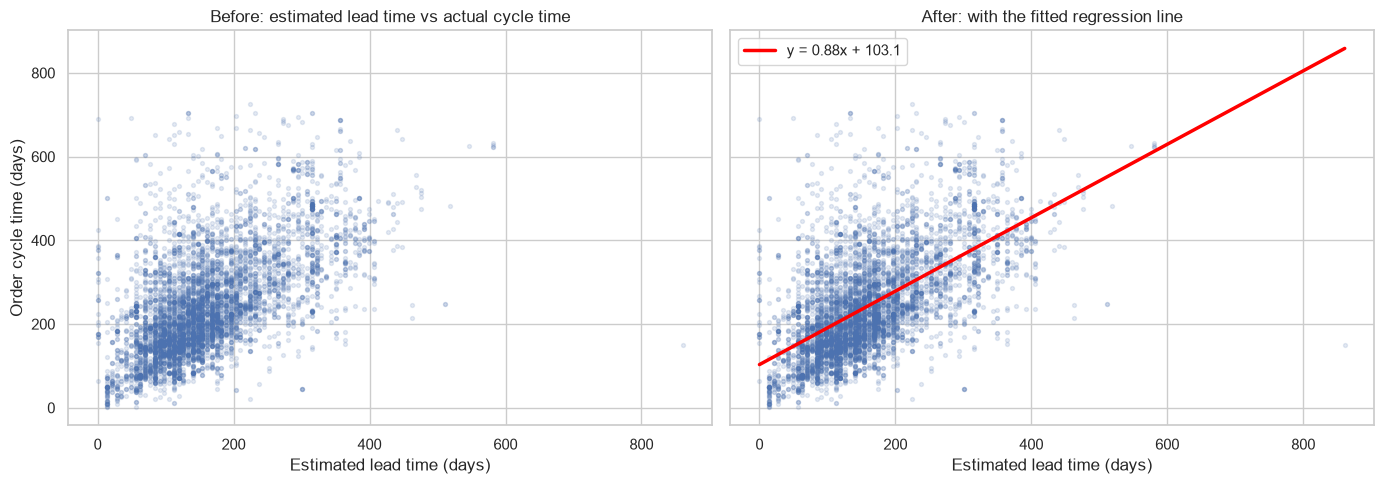

one-feature model test MSE: 9882.5


In [24]:
corr_with_target = data[["est_lead_time_days", "ordered_quantity", "unit_price", "order_year", "order_month",
                         TARGET]].corr()[TARGET].drop(TARGET)
top_feature = corr_with_target.abs().idxmax()
print("most correlated feature:", top_feature, round(corr_with_target[top_feature], 3))

one_feature_lr = LinearRegression().fit(X_train[[top_feature]], y_train)
x_line = np.linspace(X_test[top_feature].min(), X_test[top_feature].max(), 100).reshape(-1, 1)
y_line = one_feature_lr.predict(pd.DataFrame(x_line, columns=[top_feature]))

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
axes[0].scatter(X_test[top_feature], y_test, alpha=0.15, s=8)
axes[0].set_title("Before: estimated lead time vs actual cycle time")
axes[0].set_xlabel("Estimated lead time (days)")
axes[0].set_ylabel("Order cycle time (days)")

axes[1].scatter(X_test[top_feature], y_test, alpha=0.15, s=8)
axes[1].plot(x_line, y_line, color="red", linewidth=2.5,
             label=f"y = {one_feature_lr.coef_[0]:.2f}x + {one_feature_lr.intercept_:.1f}")
axes[1].set_title("After: with the fitted regression line")
axes[1].set_xlabel("Estimated lead time (days)")
axes[1].legend()
plt.tight_layout()
plt.show()

print("one-feature model test MSE:", round(mean_squared_error(y_test, one_feature_lr.predict(X_test[[top_feature]])), 1))

**Before:** there is a clear upward trend (orders with a longer estimated lead time take longer to arrive) but the points are very spread out around it.

**After:** the fitted line is about y = 0.88x + 103, so the actual cycle time is usually around 100 days longer than the lead time estimate alone would suggest. The line follows the trend but the spread around it is big (test MSE 9,883 with only this one feature), which shows why I need the other features and a non-linear model.

## 12. Which features matter most?

To check what the best model actually relies on, I use permutation importance on the test set: shuffle one input column at a time and see how much the MSE goes up. This works on the original 12 columns, so I don't have to add up the one-hot columns myself.

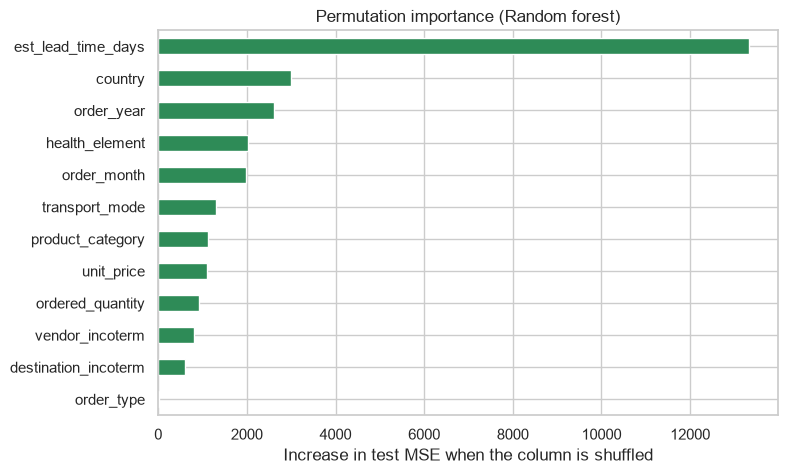

In [25]:
best_model = models[best_name]
best_pipeline = Pipeline([("preprocess", preprocessor), ("model", best_model)])

perm = permutation_importance(best_pipeline, X_test, y_test, scoring="neg_mean_squared_error",
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
importance = pd.Series(perm.importances_mean, index=FEATURES).sort_values()

plt.figure(figsize=(8, 5))
importance.plot(kind="barh", color="seagreen")
plt.xlabel("Increase in test MSE when the column is shuffled")
plt.title(f"Permutation importance ({best_name})")
plt.show()

Estimated lead time is by far the most important feature, which matches the heatmap. Country comes second, then order year, health element and month. It's interesting that year and month matter here even though their correlation in the heatmap was almost zero. Their effect just isn't a straight line: for example the median cycle time is 244 days for orders placed in 2020 (COVID) but 196 days for 2023. `order_type` has almost no importance. After cleaning it only has two values and they behave about the same, so I could drop it in a later version.

## 13. Saving the best model

I save the preprocessor and the model together as one scikit-learn `Pipeline`, so the API can send the raw values (country name, quantity, etc.) and the pipeline does the encoding, log and scaling itself.

I also save the cleaned dataset into the API folder. The `/retrain` endpoint needs it, because a random forest can't continue training like SGD can: when new data comes in it has to be refit on the old data plus the new rows.

In [26]:
MODEL_PATH = "../API/best_model.pkl"
joblib.dump(best_pipeline, MODEL_PATH, compress=3)
print(f"saved {best_name} to {MODEL_PATH} ({os.path.getsize(MODEL_PATH) / 1e6:.1f} MB)")

data.to_csv("../API/training_data.csv", index=False)
print("saved cleaned data:", data.shape)

saved Random forest to ../API/best_model.pkl (15.3 MB)
saved cleaned data: (31410, 13)


## 14. Predicting one row from the test set

This function loads the saved pipeline and predicts the cycle time for one order. It takes either a one-row DataFrame or a dictionary with the 12 inputs. I'll reuse it in the API.

In [27]:
def predict_cycle_time(row, model_path=MODEL_PATH):
    model = joblib.load(model_path)
    if isinstance(row, dict):
        row = pd.DataFrame([row])
    return float(model.predict(row[FEATURES])[0])


one_row = X_test.iloc[[0]]
display(one_row)

predicted = predict_cycle_time(one_row)
actual = y_test.iloc[0]
print(f"predicted: {predicted:.0f} days | actual: {actual} days | difference: {abs(predicted - actual):.0f} days")

,country,order_type,transport_mode,product_category,health_element,vendor_incoterm,destination_incoterm,ordered_quantity,unit_price,est_lead_time_days,order_year,order_month
27586,Uganda,Distribution Order,Air,Intrauterine Devices,Family Planning and Reproduction,Unknown,Other,175,135.0,91.0,2018,11


predicted: 191 days | actual: 300 days | difference: 109 days


In [28]:
# same thing with a dictionary, which is what the API will receive
example = one_row.iloc[0].to_dict()
print(example)
print(round(predict_cycle_time(example), 1))

{'country': 'Uganda', 'order_type': 'Distribution Order', 'transport_mode': 'Air', 'product_category': 'Intrauterine Devices', 'health_element': 'Family Planning and Reproduction', 'vendor_incoterm': 'Unknown', 'destination_incoterm': 'Other', 'ordered_quantity': 175, 'unit_price': 135.0, 'est_lead_time_days': 91.0, 'order_year': 2018, 'order_month': 11}
191.3


## 15. Notes on the results

- **Is the test loss high or low?** The best test MSE is 3,639, which is an RMSE of about 60 days. Cycle times have a median of 225 days and a standard deviation of roughly 120 days, so the model removes most of the error compared to just guessing the average. Still, 60 days is a lot for planning. It's good enough to tell a planner "this will take 6-8 months, not 4", but not precise to the week. The example row above was off by 109 days, so some orders are still hard to predict.
- **How I could reduce it:** add more detail about the supplier (the dataset only gives the incoterm), try gradient boosting (for example `HistGradientBoostingRegressor`), tune the forest more with cross-validation, and deal with the fact that 2024 orders look fast (median 122 days) only because the slow 2024 orders hadn't been delivered yet when the data was exported.
- **Retraining:** since the best model is a random forest, it can't just continue training on new rows. The `/retrain` endpoint in the API will refit it on `training_data.csv` plus the uploaded rows and swap in the new model.